# TP3 — Premier CNN sur MNIST

**Cours :** Réseaux de neurones convolutifs (CNN) — 30 h — Master 1 SDIA
**Enseignante :** Dr. Noulapeu Ngaffo Armielle — ENSPD, Université de Douala
**Durée conseillée :** 2 h · **Barème :** 10 points

---

## Objectifs

- Construire un CNN en PyTorch et l'entraîner sur CPU.
- Lire les courbes d'apprentissage et l'écart train / test.
- Repérer les erreurs du modèle et les interpréter.

## Travail demandé

1. Répondre aux 3 questions de la section « À vous » (les cellules doivent tourner).
2. Rendre le notebook exécuté.

## Mode d'emploi

- Exécuter les cellules **dans l'ordre**. L'entraînement tourne sur **CPU** : quelques minutes.
- Les cellules **« À vous »** sont évaluées.
- Toutes les graines sont fixées : deux exécutions donnent le même résultat.

In [1]:
%matplotlib inline
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(4112); np.random.seed(4112)
torch.set_num_threads(2)
device = 'cpu'
print('torch', torch.__version__, '| appareil :', device)

torch 2.15.0+cpu | appareil : cpu


## 1. Le jeu de données MNIST

70 000 chiffres manuscrits, 28×28 pixels, en niveaux de gris. On en prend un
sous-ensemble pour que l'entraînement reste rapide sur CPU (pas de GPU ici).

entrainement : 6000 images
test         : 1500 images


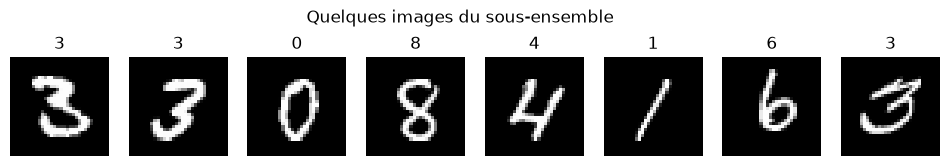

In [2]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

tf = transforms.Compose([transforms.Pad(2),
                         transforms.ToTensor(),
                         transforms.Normalize((0.1307,), (0.3081,))])
train_full = datasets.MNIST("../data", train=True, download=True, transform=tf)
test_full = datasets.MNIST("../data", train=False, download=True, transform=tf)

N_TRAIN, N_TEST = 6000, 1500
tr = Subset(train_full, range(N_TRAIN))
te = Subset(test_full, range(N_TEST))
train_loader = DataLoader(tr, batch_size=64, shuffle=True)
test_loader = DataLoader(te, batch_size=256)

print("entrainement :", len(tr), "images")
print("test         :", len(te), "images")

xb, yb = next(iter(train_loader))
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, im, yy in zip(axes, xb[:8], yb[:8]):
    ax.imshow(im[0], cmap="gray"); ax.set_title(int(yy)); ax.axis("off")
plt.suptitle("Quelques images du sous-ensemble"); plt.show()

## 2. LeNet-5, en PyTorch

L'architecture du cours : conv 5×5 (6 filtres) → pool → conv 5×5 (16) → pool →
conv 5×5 (120) → dense 84 → sortie 10.

In [3]:
class LeNet(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.c1 = nn.Conv2d(1, 6, 5)
        self.c3 = nn.Conv2d(6, 16, 5)
        self.c5 = nn.Conv2d(16, 120, 5)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, n_classes)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.c1(x)), 2)
        x = F.max_pool2d(F.relu(self.c3(x)), 2)
        x = F.relu(self.c5(x))
        x = torch.flatten(x, 1)
        x = F.relu(self.f6(x))
        return self.out(x)

modele = LeNet().to(device)
n_param = sum(p.numel() for p in modele.parameters() if p.requires_grad)
print(f"parametres entraînables : {n_param:,}".replace(",", " "))

parametres entraînables : 61 706


## 3. Entraînement

La boucle est toujours la même : sortie du modèle → perte → rétropropagation →
mise à jour des poids.

In [4]:
from tqdm.auto import tqdm
optimiseur = torch.optim.Adam(modele.parameters(), lr=1e-3)
perte_f = nn.CrossEntropyLoss()
historique = {"perte": [], "acc_train": [], "acc_test": []}

def evalue(modele, loader):
    modele.eval(); bon = tot = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            bon += (modele(x).argmax(1) == y).sum().item(); tot += y.size(0)
    return bon / tot

EPOQUES = 3
for ep in range(EPOQUES):
    modele.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimiseur.zero_grad()
        perte = perte_f(modele(x), y)
        perte.backward(); optimiseur.step()
        historique["perte"].append(perte.item())
    a_tr = evalue(modele, train_loader); a_te = evalue(modele, test_loader)
    historique["acc_train"].append(a_tr); historique["acc_test"].append(a_te)
    print(f"epoque {ep+1}/{EPOQUES}  perte={np.mean(historique['perte'][-94:]):.4f}"
          f"  train={a_tr:.1%}  test={a_te:.1%}")

print("\nexactitude finale sur le test :", f"{historique['acc_test'][-1]:.1%}")

C:\Users\HP\Documents\cours-cnn-30h\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


epoque 1/3  perte=0.9425  train=89.5%  test=85.9%


epoque 2/3  perte=0.2761  train=94.3%  test=91.2%


epoque 3/3  perte=0.1754  train=95.9%  test=93.6%

exactitude finale sur le test : 93.6%


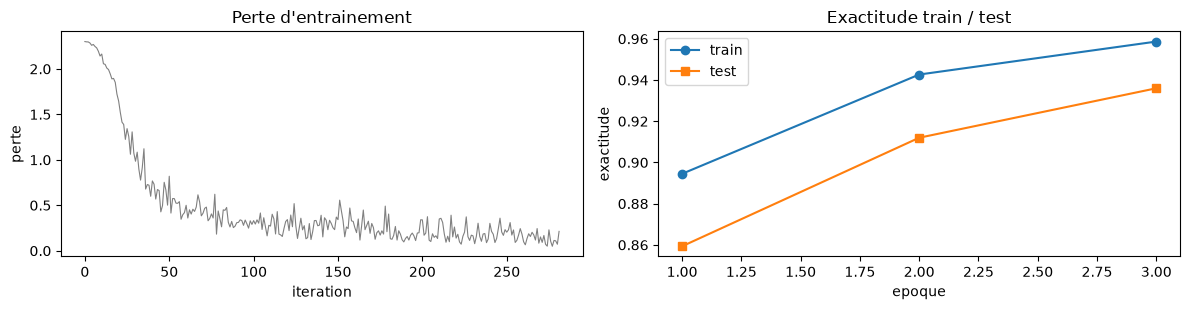

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].plot(historique["perte"], lw=.8, color="grey")
axes[0].set_xlabel("iteration"); axes[0].set_ylabel("perte"); axes[0].set_title("Perte d'entrainement")
axes[1].plot(range(1, EPOQUES+1), historique["acc_train"], "o-", label="train")
axes[1].plot(range(1, EPOQUES+1), historique["acc_test"], "s-", label="test")
axes[1].set_xlabel("epoque"); axes[1].set_ylabel("exactitude"); axes[1].legend()
axes[1].set_title("Exactitude train / test")
plt.tight_layout(); plt.show()

## 4. Où le modèle se trompe-t-il ?

On regarde les erreurs : c'est souvent plus instructif que le score global.

erreurs affichees : 8 sur 256


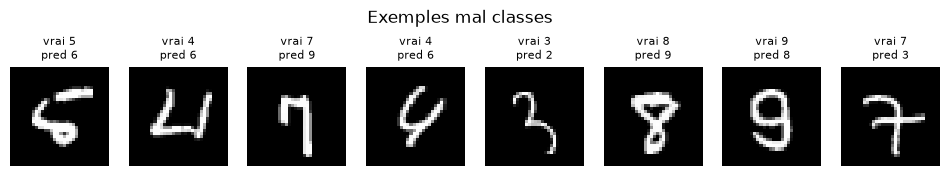

In [6]:
modele.eval()
x, y = next(iter(test_loader))
with torch.no_grad():
    pred = modele(x).argmax(1)
faux = (pred != y).nonzero().flatten()[:8]
print("erreurs affichees :", len(faux), "sur", len(y))

fig, axes = plt.subplots(1, 8, figsize=(12, 2.2))
for ax, i in zip(axes, faux):
    ax.imshow(x[i][0], cmap="gray")
    ax.set_title(f"vrai {int(y[i])}\npred {int(pred[i])}", fontsize=8)
    ax.axis("off")
plt.suptitle("Exemples mal classes"); plt.show()

## 5. À vous

**Question 1.** Quelle est la forme du tenseur d'entrée de la première couche
convolutive ? Combien de paramètres contient `c1` ?

**Question 2.** Ajoutez une couche de dropout (p = 0,5) après `f6` et relancez
l'entraînement. L'exactitude de test progresse-t-elle ?

**Question 3.** Remplacez `max_pool2d` par `avg_pool2d` : quel est l'effet ?

In [7]:
# ---- À VOUS ----
# 1) forme : (N, C, H, W) = ...
#    parametres de c1 = K*K*Cin*Cout + Cout = ...
print("parametres de c1 :", sum(p.numel() for p in modele.c1.parameters()))

# 2) a completer : ajouter nn.Dropout(0.5) et relancer

# 3) a completer : remplacer max_pool2d par avg_pool2d

parametres de c1 : 156


## 6. Synthèse

| Étape | Rôle |
|---|---|
| `Conv2d` | extrait des caractéristiques locales |
| `ReLU` | introduit la non-linéarité |
| `MaxPool2d` | réduit la résolution, sans paramètre |
| `Flatten` | transforme le tenseur en vecteur |
| `Linear` | décide à partir des caractéristiques |

**Repère :** LeNet-5 complet ≈ 61 000 paramètres. Un MLP sur les mêmes 784 entrées en
demanderait 784 000 pour une seule couche.